## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Yifan Qiao

**Date:** 10/13/26

Q1.1


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1, noise, N),
                   np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N),
                   np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N),
                   np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0,:], 'x2': X1[1,:], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0,:], 'x2': X2[1,:], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0,:], 'x2': X3[1,:], 'group': 'c'})

    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

/Users/oceane/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/oceane/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Q1.2

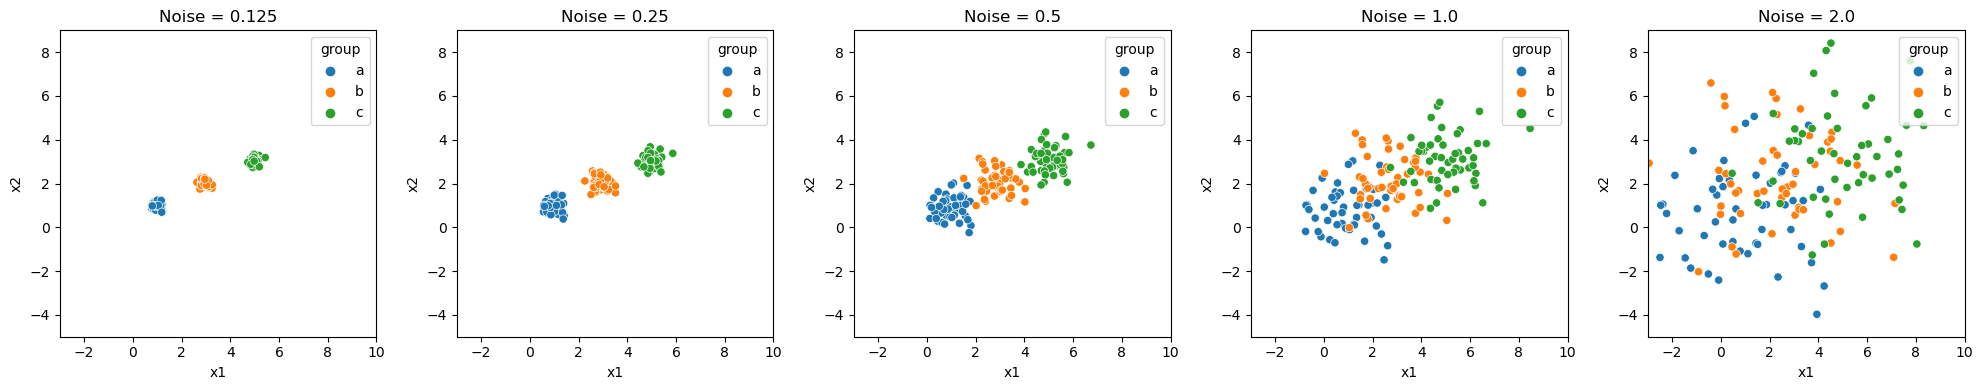

In [3]:
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, df, noise in zip(axes, datasets, noises):
    sns.scatterplot(data=df, x='x1', y='x2',
                    hue='group', ax=ax)
    ax.set_title(f'Noise = {noise}')
    ax.set_xlim(-3, 10)
    ax.set_ylim(-5, 9)

plt.tight_layout()
plt.show()

As noise increases, the clusters become less distinct. With low noise, the three groups are clearly separated. As noise increases, the points spread out and overlap more. At noise = 2.0, it becomes difficult to visually distinguish the groups.

Q1.3

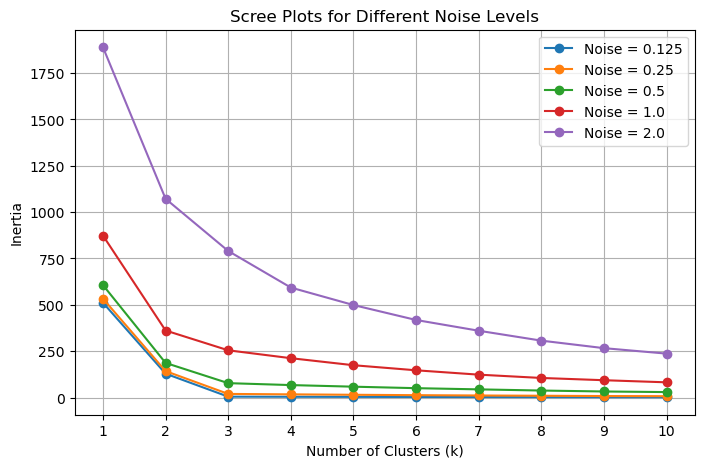

In [4]:
plt.figure(figsize=(8, 5))

for df, noise in zip(datasets, noises):
    X = df[['x1', 'x2']]

    inertia = []
    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia.append(model.inertia_)

    plt.plot(range(1, 11), inertia, marker='o',
             label=f'Noise = {noise}')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plots for Different Noise Levels')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

With low noise, the scree plot has a clearer elbow around k = 3. As noise increases, the elbow becomes less obvious because the clusters overlap more. This makes it harder to choose the best k. At high noise levels, there may not be one clear choice.

Q1.4

The elbow is the point where adding more clusters stops making a big improvement. In this simulation, we created three groups, so k = 3 is a natural choice when noise is low. Going from one to three clusters greatly reduces inertia, but adding more clusters gives smaller improvements. When noise is high, the groups overlap, so the elbow becomes harder to identify.

Q2.1

In [5]:
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

print(df.columns.tolist())
df.head()

['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [6]:
df = df[df['Year'] == 2020].copy()
df = df.dropna()

print('Number of countries:', len(df))

cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']

print(df[cols].dtypes)
print(df[cols].isna().sum())

df.head()

Number of countries: 148
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


After filtering the data to 2020 and dropping missing values, I have 148 countries. All four variables are numeric and have no missing values, so no further cleaning is needed.

Q2.2

In [7]:
cols2 = ['Spending (2020 USD)', 'Spending per Capita']

scaler = MinMaxScaler()

X2 = scaler.fit_transform(df[cols2])
X2 = pd.DataFrame(X2, columns=cols2, index=df.index)

X2.head()

,Spending (2020 USD),Spending per Capita
32,0.000348,0.002620
66,0.000230,0.025615
100,0.012461,0.087630
134,0.001265,0.011767
168,0.003626,0.024627


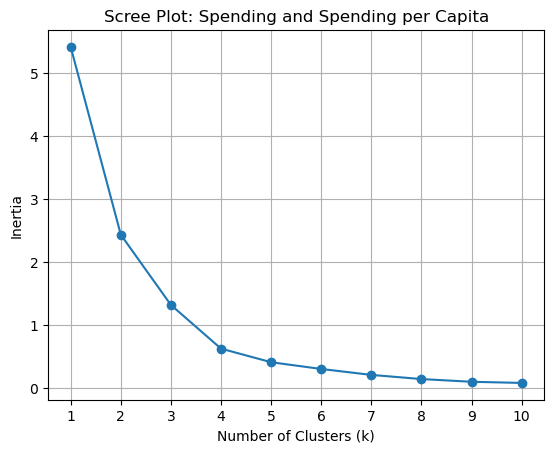

In [8]:
inertia2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    inertia2.append(model.inertia_)

plt.plot(range(1, 11), inertia2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Based on the scree plot, I chose k = 4 because inertia decreases a lot from k = 1 to k = 4, but the decrease becomes much smaller after k = 4.

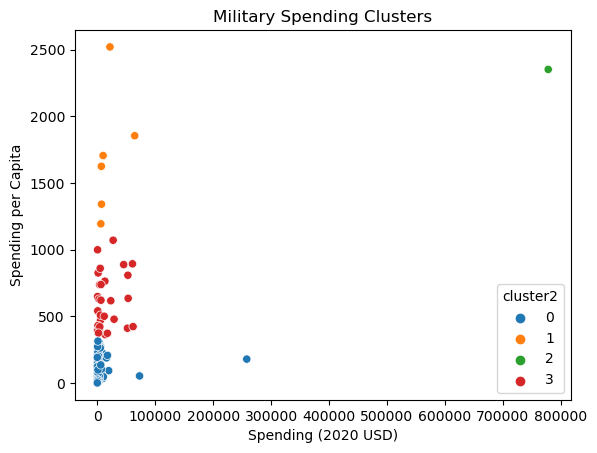

In [9]:
k2 = 4

model2 = KMeans(n_clusters=k2, random_state=42, n_init=10)
df['cluster2'] = model2.fit_predict(X2)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster2',
    palette='tab10'
)

plt.title('Military Spending Clusters')
plt.show()

In [10]:
df.groupby('cluster2')[cols2].describe()

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      111.0    4859.185065  25405.739131       8.622460   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                        1.0  778397.200000           NaN  778397.200000   
3                       30.0   17077.591354  20583.053357     405.790494   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            130.010211     382.464677    2297.032353  257973.429834   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   
3           2294.039665    5857.060906   26296.001003   61712.537169   

         Spending per Capita                                        \
                       count         mean         std          min   
cluster2                                                             
0                      111.0    80.061470   83.501824     0.580129   
1                        6.0  1706.721916  466.375705  1193.598730   
2                        1.0  2351.631858         NaN  2351.631858   
3                       30.0   607.478618  206.928757   362.467076   

                                                              
                  25%          50%          75%          max  
cluster2                                                      
0           14.880549    47.056944   125.387558   314.201312  
1         1412.083201  1665.447478  1817.219993  2520.398541  
2         2351.631858  2351.631858  2351.631858  2351.631858  
3          422.208252   579.004604   757.328513  1070.623322

In [11]:
print(df['cluster2'].value_counts().sort_index())

df[df['Country'].str.contains('United States', case=False, na=False)][
    ['Country', 'cluster2'] + cols2
]

cluster2
0    111
1      6
2      1
3     30
Name: count, dtype: int64


,Country,cluster2,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


The clustering results show four different spending patterns. Cluster 0 contains most countries, with relatively low total spending and spending per capita. Cluster 1 has only 6 countries with very high spending per capita. Cluster 3 has 30 countries with moderate spending per capita. The United States is the only country in Cluster 2, with the highest total military spending. Overall, most countries spend relatively little, while a few countries have much higher military spending.

Q2.3

In [12]:
cols3 = ['Percent of Government Spending', 'Percent of GDP']

X3 = scaler.fit_transform(df[cols3])
X3 = pd.DataFrame(X3, columns=cols3, index=df.index)

X3.head()

,Percent of Government Spending,Percent of GDP
32,0.150377,0.137524
66,0.110877,0.127303
100,0.566960,0.676168
134,0.233882,0.146191
168,0.041498,0.073306


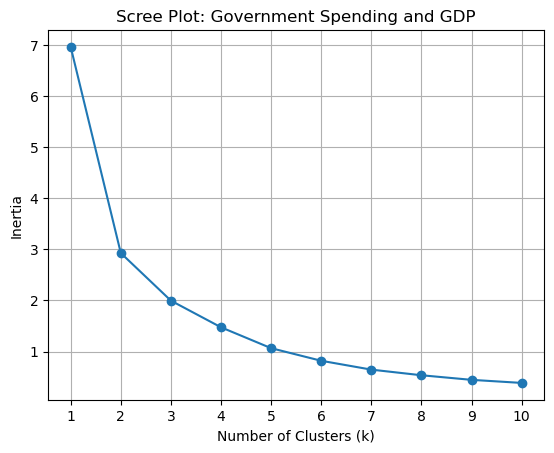

In [13]:
inertia3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X3)
    inertia3.append(model.inertia_)

plt.plot(range(1, 11), inertia3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Government Spending and GDP')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Based on the scree plot, I chose k = 2.

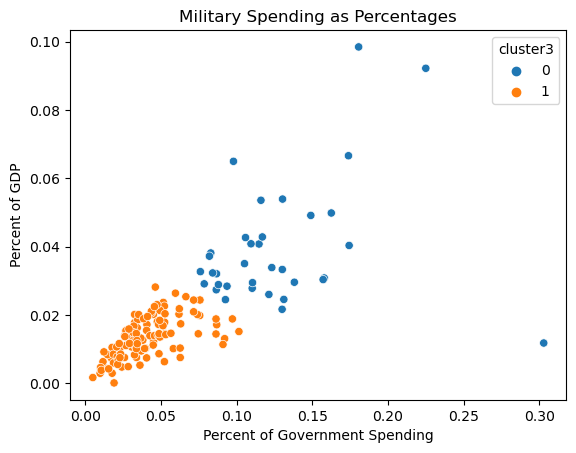

In [14]:
k3 = 2

model3 = KMeans(n_clusters=k3, random_state=42, n_init=10)
df['cluster3'] = model3.fit_predict(X3)

sns.scatterplot(
    data=df,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='cluster3',
    palette='tab10'
)

plt.title('Military Spending as Percentages')
plt.show()

In [15]:
df.groupby('cluster3')[cols3].describe()

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  35.0  0.126456  0.046209  0.076005   
1                                 113.0  0.041394  0.020681  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.093093  0.116052  0.143584  0.303027           35.0  0.039433   
1         0.026783  0.038486  0.051496  0.101501          113.0  0.013481   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.018179  0.011742  0.028962  0.033281  0.042722  0.098470  
1         0.005966  0.000054  0.009147  0.013631  0.017830  0.028132

In [16]:
df['cluster3'].value_counts().sort_index()

cluster3
0     35
1    113
Name: count, dtype: int64

The two clusters show different levels of military spending relative to government spending and GDP. Cluster 0 contains 35 countries with higher percentages, while Cluster 1 contains 113 countries with lower percentages. Most countries are in Cluster 1, suggesting that they spend a relatively smaller share of their resources on the military.

Part 2 uses total spending and spending per capita, while Part 3 uses spending as a percentage of government spending and GDP. Part 2 divides countries into four clusters, but Part 3 divides them into two. This shows that countries can be grouped differently depending on whether we look at the amount of money spent or the percentage of their resources spent on the military.

Q2.4

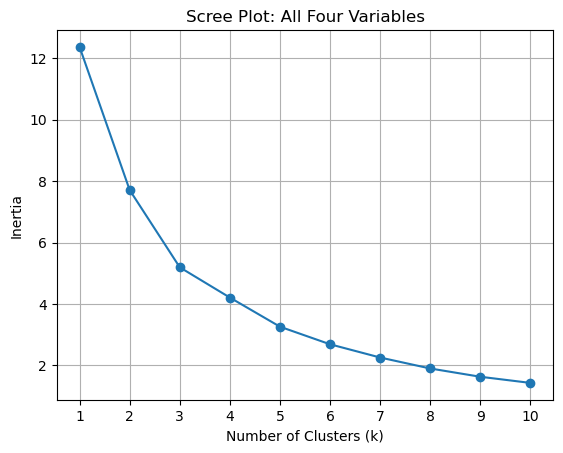

In [17]:
cols4 = ['Spending (2020 USD)', 'Spending per Capita',
         'Percent of Government Spending', 'Percent of GDP']

X4 = scaler.fit_transform(df[cols4])
X4 = pd.DataFrame(X4, columns=cols4, index=df.index)

inertia4 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X4)
    inertia4.append(model.inertia_)

plt.plot(range(1, 11), inertia4, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: All Four Variables')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Based on the scree plot, I chose k = 3 because inertia decreases quickly from k = 1 to k = 3, but the decrease becomes slower after that.

In [19]:
k4 = 3

model4 = KMeans(n_clusters=k4, random_state=42, n_init=10)
df['cluster4'] = model4.fit_predict(X4)

df.groupby('cluster4')[cols4].describe()

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster4                                   ...                                  
0                       31.0   212.689100  ...                       0.134663   
1                        6.0  1875.150751  ...                       0.164503   
2                      111.0   196.926833  ...                       0.050505   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster4                                                                    
0         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
1         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   

                                        
               50%       75%       max  
cluster4                                
0         0.032024  0.040531  0.066600  
1         0.059257  0.085398  0.098470  
2         0.013589  0.017769  0.028132  

[3 rows x 32 columns]

In [20]:
print(df['cluster4'].value_counts().sort_index())

df.groupby('cluster4')[cols4].mean().round(2)

cluster4
0     31
1      6
2    111
Name: count, dtype: int64


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster4,,,,
0,8786.09,212.69,0.12,0.03
1,147964.58,1875.15,0.14,0.06
2,7086.47,196.93,0.04,0.01


In [21]:
pd.crosstab(df['cluster2'], df['cluster4'])

cluster4,0,1,2
cluster2,,,
0,26,0,85
1,0,5,1
2,0,1,0
3,5,0,25


In [22]:
pd.crosstab(df['cluster3'], df['cluster4'])

cluster4,0,1,2
cluster3,,,
0,29,6,0
1,2,0,111


Using all four variables, K-means divides the countries into three clusters. Cluster 1 contains 6 countries with high military spending, including the United States. Cluster 2 contains 111 countries with relatively low spending, while Cluster 0 contains 31 countries with higher spending percentages.

Compared to Part 2, the United States is no longer in a cluster by itself. Compared to Part 3, the 35 countries with higher spending percentages are divided into two groups.

Q2.5

I think K-means is useful for finding patterns in military spending. It helps group countries with similar spending levels and makes it easier to compare them. For example, we can see that most countries have relatively low military spending, while a small number of countries spend much more.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** a471818e7a413ce0dfff9386d5db86c37be670a6
- **AI tool and model used:** ChatGPT (OpenAI, GPT-6)

### *Prompts used

1. Review my Phase 1 solutions for Q1 and Q2 on K-means clustering. Identify any mistakes or areas that could be improved, especially in choosing k and interpreting the clusters.

2. Suggest simple improvements to my explanations and help me compare the clustering results across different variables.

### *AI-proposed changes


1. Explain that the elbow method is subjective and does not always give one clear optimal k.

2. Use the cluster counts and mean values to support the interpretations instead of only describing the scatterplots.

3. Make the comparison between Q2.2, Q2.3, and Q2.4 more specific by using the crosstab results.

4. Clarify that K-means identifies similarities between countries but cannot explain the reasons behind their military spending.

### *Evaluation of AI suggestions


Change	Decision	Reason and verification
1	Accept	The scree plots do not always have a clear elbow.
2	Accept	I checked the cluster counts and mean values.
3	Accept	The crosstabs show how cluster membership changes.
4	Accept	K-means describes patterns but does not explain causes.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Q1.3 & Q1.4 add:

The elbow method helps us choose k by finding where inertia starts decreasing more slowly. With low noise, k = 3 is a reasonable choice because the three groups are clearly separated. With higher noise, the elbow becomes less clear, so choosing k is more subjective.

Q2.4 Comparison：

Using all four variables gives three clusters. Compared to Part 2, the United States is no longer alone and is grouped with five other countries. Compared to Part 3, the 35 countries with higher spending percentages are divided into two groups. This shows that using different variables changes the clustering results.

Q2.5 Usefulness：

K-means helps identify countries with similar military spending patterns. Most countries have relatively low spending, while a few have much higher spending. However, the results depend on the variables and the chosen k. K-means cannot explain why countries spend different amounts.

### *Reflection on AI assistance
In your own words without generative AI.

With the help of AI, I learned to be more careful when choosing the elbow and to use describe tables and crosstabs to support my conclusions. I also learned that AI is not always good at choosing the best k, so we still need to check the plots and make our own decisions. Also, K-means is sensitive to the choice of variables, normalization, and k. It cannot explain why countries have different levels of military spending.